# 12 · How precisely can Lazuli measure a 1-minute He I 10830 Å emission flash on a Sun-like star: with the IFS, or with a new 5 nm WCC filter?

The He I 10830 Å triplet is a chromospheric activity diagnostic (and, in transit, a tracer of escaping exoplanet atmospheres; arXiv:1711.05269). Here a G2V star shows a **transient emission line at 10830 Å, intrinsic FWHM 0.1 Å, that lasts exactly one 1-minute exposure**. We ask for the 1σ accuracy of the line flux in that minute versus the star's z′ (AB) magnitude, with the star's own photon noise included, for:

- the **IFS** (`slicersim`), measuring the line in the R ≈ 100 spectrum;
- the **WCC** with a **new, hypothetical 5 nm top-hat filter** centred on 10830 Å, on the **qCMOS (HWK4123)** sensor (`wcc_etc` `qcmos:` noise model). The filter does not exist in `wcc_etc`; we build it.

The line is unresolved by both instruments, so what matters is its flux (or equivalent width, EW) against the noise of the star under it. The notebook ends by adapting WCC tutorial 05 (light curves): a 1-minute-cadence time series containing the flash.

**Instrument / code:** Lazuli IFS, `slicersim` (`LazuliTarget`, `change_detector`); Lazuli WCC, `wcc_etc` (`Simulation.from_sensorfilter("qcmos:z")`, `set_sensor` on a top-hat throughput, both gain modes, `get_scene("emission", host=...)`).

## Prompt to try in Jupyter AI

> A G2V star (z′ AB from 4 to 18) shows a He I 10830 Å emission line, FWHM 0.1 Å, for one 1-minute exposure.
> (1) With `slicersim.LazuliTarget`, measure the line flux in the IFS spectrum over ±1 LSF FWHM, with the star's photon noise, choosing for each magnitude a ~1-minute MACC read-out that does not saturate. Bin-integrate the line onto the IFS wavelength bins first.
> (2) With `wcc_etc`, build a 5 nm top-hat filter at 10830 Å on the `qcmos` sensor from the `qcmos:z` throughput, rebuild the sensor on it with `get_sensor_config` + `set_sensor`, check that it took effect, and get the line S/N with `get_scene("emission", lines=[...], host="G2V")` in both qCMOS gain modes, splitting the minute into reads to avoid saturation.
> Plot σ(EW) per minute versus z′ for both, and a 1-minute-cadence light curve with the flash at z′ = 10. State what is assumed about the continuum.

## Setup

Two gotchas, both checked below:

- **slicersim samples a custom spectrum at the centre of each IFS wavelength bin** (gallery notebook 06). A 0.1 Å line would fall between samples and silently disappear, so we integrate the line over each IFS bin analytically before handing the spectrum over.
- **The new WCC filter** is written as a throughput file in the same format as the shipped `qcmos:z` curve, and the qCMOS sensor is rebuilt on it (`update_sensor` would not do: the bandpass is read when the sensor is created). Section 3 verifies that the ETC actually uses it before any number is computed.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if os.path.isdir(SRC) and not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory (off the hub, sncosmo's default is kept)
if os.path.isdir(DEST):
    os.environ['SNCOSMO_DATA_DIR'] = DEST

import importlib
import tempfile
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import astropy.units as u
import matplotlib.pyplot as plt
from scipy.special import erf
import slicersim
import wcc_etc
from wcc_etc import Simulation, get_scene

print('slicersim', slicersim.__version__, '| wcc_etc', wcc_etc.__version__)
warnings.filterwarnings('ignore', message='spectrum')    # line-only spectra do not cover the whole filter: expected (WCC exercise 4)
trapezoid = getattr(np, 'trapezoid', None) or np.trapz

THUMB = Path('thumbs/12_he10830_transient_ifs_vs_wcc.png')
LINE_WAVE = 10830.0        # Å, He I triplet (air)
LINE_FWHM = 0.1            # Å, intrinsic; unresolved by both instruments
LINE_PEAK = 1.0            # line peak / local continuum: sets the *reference* line only (σ(EW) does not depend on it)
EW_REF = LINE_PEAK * LINE_FWHM * np.sqrt(np.pi / (4 * np.log(2)))     # Å; Gaussian EW = 1.0645 x FWHM x peak
T_EXP = 60.0               # s: the flash lasts one exposure
STAR = 'G2V'
MAG_BAND, MAG_SYS = 'sdss_z', 'abmag'     # z' (AB)
FILTER_WIDTH = 50.0        # Å, top hat
BASE_LABEL = 'qcmos:z'     # HWK4123 qCMOS in z: telescope x QE at 1.08 µm and the sensor noise model
Z_GRID = np.arange(4.0, 18.01, 0.25)
Z0 = 14.0                  # reference magnitude for the calibration runs
print(f"reference line: FWHM {LINE_FWHM} Å, peak {LINE_PEAK} x continuum -> EW = {EW_REF * 1e3:.0f} mÅ")

slicersim 1.4.2 | wcc_etc 0.1.1
reference line: FWHM 0.1 Å, peak 1.0 x continuum -> EW = 106 mÅ


## 1. The star and the line

Both instruments see the same spectrum: the `wcc_etc` G2V (Pickles) template normalised to z′ (AB), evaluated from 3000 to 20 000 Å and handed to slicersim as an absolute flux. The line flux scales with the star: $F_\mathrm{line} = \mathrm{EW}\times F_\lambda^\mathrm{cont}(10830)$, with the continuum averaged over the 50 Å filter window.

In [2]:
LAM = np.arange(3000.0, 20000.0, 1.0)

def star_scene(z, **kw):
    return get_scene(STAR, mag=float(z), bandpass=MAG_BAND, magsys=MAG_SYS, **kw)

_, flam = star_scene(Z0).source.get_spectrum(as_array=True, wave=LAM * u.AA, flux_unit='flam')
FLAM_Z0 = np.asarray(getattr(flam, 'value', flam), dtype=float)       # erg/s/cm2/Å at z' = Z0
assert np.all(np.isfinite(FLAM_Z0)) and np.all(FLAM_Z0 > 0), 'the G2V template does not cover 3000-20000 Å'
IN_BAND = np.abs(LAM - LINE_WAVE) <= FILTER_WIDTH / 2
FCONT_Z0 = FLAM_Z0[IN_BAND].mean()

def scale(z):
    return 10 ** (-0.4 * (np.asarray(z) - Z0))

def fcont(z):
    return FCONT_Z0 * scale(z)                # erg/s/cm2/Å under the line

def line_flux(z, ew=EW_REF):
    return ew * fcont(z)                      # erg/s/cm2

print(f"G2V at z' = {Z0}: continuum at {LINE_WAVE:.0f} Å = {FCONT_Z0:.3e} erg/s/cm2/Å; reference line flux = {line_flux(Z0):.3e} erg/s/cm2")

# cross-check the normalisation with sncosmo's SDSS z' (photon-weighted AB magnitude)
try:
    import sncosmo
    band = sncosmo.get_bandpass('sdssz')
    w = LAM[(LAM > band.minwave()) & (LAM < band.maxwave())]
    T = band(w)
    f_ab = 3631e-23 * 2.998e18 / w ** 2
    z_syn = -2.5 * np.log10(trapezoid(np.interp(w, LAM, FLAM_Z0) * T * w, w) / trapezoid(f_ab * T * w, w))
    print(f"sncosmo sdssz synthetic magnitude of the spectrum: {z_syn:.3f} (asked for {Z0})")
except Exception as err:                       # informational only
    print('sncosmo cross-check skipped:', err)

G2V at z' = 14.0: continuum at 10830 Å = 1.245e-15 erg/s/cm2/Å; reference line flux = 1.326e-16 erg/s/cm2


sncosmo cross-check skipped: <urlopen error Tunnel connection failed: 403 Forbidden>


## 2. The IFS (slicersim)

The star is a point source in the narrow field. The H4RG is read up the ramp every $t_\mathrm{frame}$ = 2.83 s; one minute is ~21 frames. Bright stars need shorter ramps, repeated, which pays the read noise more often. The candidate ~1-minute read-outs are listed below; for each magnitude we take the one with the smallest error that does not saturate.

**Measurement** (as in gallery notebook 06): line signal = (spectrum with line) − (spectrum without) summed over ±1 LSF FWHM, times the bin width; noise = $\sqrt{\sum \sigma^2\,d\lambda^2}$ from the variance of the spectrum *with* the line, so the star's (and the line's) photon noise is in. Subtracting the noise-free continuum means **the continuum is assumed known** from the quiescent exposures before the flash (a long baseline; with a single reference exposure the error grows by √2).

The variance is linear in the star flux and in the line flux, so three noise-free runs per read-out (star, star + line, no star) give the error at every magnitude; a full run at two magnitudes checks this.

In [3]:
probe = slicersim.LazuliTarget(LAM, FLAM_Z0)
LB = probe.simulation.spectrograph.lbda
EDGES = np.r_[LB[0] - (LB[1] - LB[0]) / 2, (LB[1:] + LB[:-1]) / 2, LB[-1] + (LB[-1] - LB[-2]) / 2]
IDX = np.searchsorted(EDGES, LAM)              # label i <-> IFS bin between EDGES[i-1] and EDGES[i]
NB = len(EDGES) + 1
SIG_LINE = LINE_FWHM / (2 * np.sqrt(2 * np.log(2)))

def bin_average(flux):
    mean = np.bincount(IDX, flux, minlength=NB) / np.maximum(np.bincount(IDX, minlength=NB), 1)
    return mean[IDX]

def line_per_bin(F):
    # Gaussian line of total flux F integrated exactly over each IFS bin -> bin-mean flux density (erg/s/cm2/Å)
    cdf = 0.5 * (1 + erf((EDGES - LINE_WAVE) / (np.sqrt(2) * SIG_LINE)))
    return np.r_[0.0, F * np.diff(cdf) / np.diff(EDGES), 0.0]

def line_binned(F):
    return line_per_bin(F)[IDX]                 # on the LAM grid, constant within each IFS bin

STAR_BINNED = bin_average(FLAM_Z0)
assert np.isclose(np.sum(line_per_bin(1.0)[1:-1] * np.diff(EDGES)), 1.0), 'line flux not conserved'

lr, R = probe.simulation.get_resolving_power()
R_LINE = np.interp(LINE_WAVE, lr, R)
FWHM_LSF = LINE_WAVE / R_LINE
DL = np.gradient(LB)
WIN = np.abs(LB - LINE_WAVE) <= FWHM_LSF
TFRAME = probe.get_properties('tframe')
print(f"IFS at {LINE_WAVE:.0f} Å: R = {R_LINE:.0f}, LSF FWHM = {FWHM_LSF:.0f} Å, pixel = {np.interp(LINE_WAVE, LB, DL):.0f} Å, "
      f"window ±1 FWHM = {WIN.sum()} bins; t_frame = {TFRAME} s")
print(f"the 0.1 Å line is diluted ~{FWHM_LSF / LINE_FWHM:.0f}x by the LSF")

READOUTS = [((21, 1, 0), 1), ((7, 1, 0), 3), ((3, 1, 0), 7), ((2, 1, 0), 10)]    # ~1 min each, shortest ramps last
for (n, m, d), nr in READOUTS:
    print(f"nmd = {(n, m, d)!s:11s} x {nr:2d} ramps: {nr * (n * (m + d) - d) * TFRAME:5.1f} s")

IFS at 10830 Å: R = 102, LSF FWHM = 107 Å, pixel = 46 Å, window ±1 FWHM = 5 bins; t_frame = 2.83 s
the 0.1 Å line is diluted ~1065x by the LSF
nmd = (21, 1, 0)  x  1 ramps:  59.4 s
nmd = (7, 1, 0)   x  3 ramps:  59.4 s
nmd = (3, 1, 0)   x  7 ramps:  59.4 s
nmd = (2, 1, 0)   x 10 ramps:  56.6 s


In [4]:
def ifs_run(flux, nmd, nramps):
    # noise-free spectrum, its variance (flambda), saturation flag and exposure time
    t = slicersim.LazuliTarget(LAM, flux)
    t.change_detector(nmd=nmd, nramps=nramps)
    _, f, v = t.get_spectrum(unit='flambda', incl_error=False)
    return f, v, bool(t.simulation.detector.nsaturated_detpx), t.get_exposure_time()

def wsum(v):
    return np.sum(v[WIN] * DL[WIN] ** 2)

F0 = line_flux(Z0)
IFS_MODEL = {}
for ro in READOUTS:
    f_c, v_c, sat, texp = ifs_run(STAR_BINNED, *ro)                     # star at Z0
    f_l, v_l, _, _ = ifs_run(STAR_BINNED + line_binned(F0), *ro)         # star + line
    _, v_0, _, _ = ifs_run(STAR_BINNED * 1e-8, *ro)                       # no star: zodi + dark + read noise
    assert not sat, f'{ro} saturates at the calibration magnitude z = {Z0}'
    n0 = wsum(v_0)
    IFS_MODEL[ro] = dict(n0=n0, a=wsum(v_c) - n0, k=(wsum(v_l) - wsum(v_c)) / F0,
                         eff=np.sum((f_l - f_c)[WIN] * DL[WIN]) / F0, texp=texp)
    m = IFS_MODEL[ro]
    print(f"{ro[0]!s:11s} x {ro[1]:2d}: {texp:5.1f} s, line recovered in the window {m['eff']:.0%}, "
          f"variance at z' = {Z0}: star {m['a'] / (m['a'] + m['n0']):.0%}, detector + zodi {m['n0'] / (m['a'] + m['n0']):.0%}")

def ifs_sigma_F(z, ro, F=None):
    # 1-sigma error on the true line flux (erg/s/cm2) in one read-out, star at z'
    m = IFS_MODEL[ro]
    F = line_flux(z) if F is None else F
    return np.sqrt(m['n0'] + m['a'] * scale(z) + m['k'] * F) / m['eff']

# check the linear model against full runs
for z in (12.0, 16.0):
    F = line_flux(z)
    f_c, _, _, _ = ifs_run(STAR_BINNED * scale(z), *READOUTS[0])
    f_l, v_l, _, _ = ifs_run(STAR_BINNED * scale(z) + line_binned(F), *READOUTS[0])
    full = np.sqrt(wsum(v_l)) / np.sum((f_l - f_c)[WIN] * DL[WIN]) * F
    print(f"z' = {z}: sigma_F full run {full:.3e}, linear model {ifs_sigma_F(z, READOUTS[0]):.3e} erg/s/cm2")
    assert np.isclose(full, ifs_sigma_F(z, READOUTS[0]), rtol=0.03)

(21, 1, 0)  x  1:  59.4 s, line recovered in the window 98%, variance at z' = 14.0: star 98%, detector + zodi 2%


(7, 1, 0)   x  3:  59.4 s, line recovered in the window 98%, variance at z' = 14.0: star 84%, detector + zodi 16%


(3, 1, 0)   x  7:  59.4 s, line recovered in the window 98%, variance at z' = 14.0: star 53%, detector + zodi 47%


(2, 1, 0)   x 10:  56.6 s, line recovered in the window 98%, variance at z' = 14.0: star 37%, detector + zodi 63%


z' = 12.0: sigma_F full run 1.546e-15, linear model 1.565e-15 erg/s/cm2


z' = 16.0: sigma_F full run 2.728e-16, linear model 2.654e-16 erg/s/cm2


**Bright limit.** For each read-out, bisect in z′ for the magnitude where the first detector pixel saturates (gallery notebook 07's criterion, `detector.nsaturated_detpx`).

In [5]:
def ifs_saturates(z, ro):
    return ifs_run(STAR_BINNED * scale(z), *ro)[2]

def ifs_bright_limit(ro, lo=2.0, hi=Z0, tol=0.05):
    if not ifs_saturates(lo, ro):
        return lo
    while hi - lo > tol:                         # lo saturates, hi does not
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if ifs_saturates(mid, ro) else (lo, mid)
    return hi

IFS_SAT = {ro: ifs_bright_limit(ro) for ro in READOUTS}
for ro, zs in IFS_SAT.items():
    print(f"{ro[0]!s:11s} x {ro[1]:2d}: unsaturated for z' > {zs:.2f}")

ifs_sigF = np.full(Z_GRID.size, np.nan)
ifs_ro = [None] * Z_GRID.size
for i, z in enumerate(Z_GRID):
    ok = [ro for ro in READOUTS if z > IFS_SAT[ro]]
    if ok:
        best = min(ok, key=lambda ro: ifs_sigma_F(z, ro))
        ifs_sigF[i], ifs_ro[i] = ifs_sigma_F(z, best), best
ifs_sigEW = ifs_sigF / fcont(Z_GRID)           # Å

(21, 1, 0)  x  1: unsaturated for z' > 11.09
(7, 1, 0)   x  3: unsaturated for z' > 9.78
(3, 1, 0)   x  7: unsaturated for z' > 8.56
(2, 1, 0)   x 10: unsaturated for z' > 7.81


## 3. The WCC: a new 5 nm top-hat filter on the qCMOS (HWK4123)

`qcmos:z` has total throughput = telescope × z′ filter × HWK4123 QE (a CSV in nm shipped with `wcc_etc`). The new filter is a **top hat from 10805 to 10855 Å whose transmission equals the z′ filter's at 1.08 µm**, i.e. the new total throughput is the `qcmos:z` curve inside the top hat and zero outside. The sensor noise model is unchanged. The HWK4123 has two gain modes and we keep the better one at each magnitude:

- **high** (32×): measured read noise 0.25 e⁻ (doubled in the config as a margin), but the 12-bit ADC clips at ≈ 552 e⁻;
- **low** (1×): read noise 2.33 e⁻ (doubled), 7500 e⁻ well.

First, what the shipped `qcmos:z` curve says at 10830 Å: silicon QE is falling steeply here.

qcmos:z: pivot 9040 Å, total throughput at 10830 Å = 0.0028 (curve peak 0.194); PSF AiryPSF; min frame 0.008 s
  gain high: read noise 0.50 electron / pix, saturation 552 electron (adc limited), dark 0.05 electron / (pix s)
  gain low : read noise 4.66 electron / pix, saturation 7500 electron (well limited), dark 0.05 electron / (pix s)


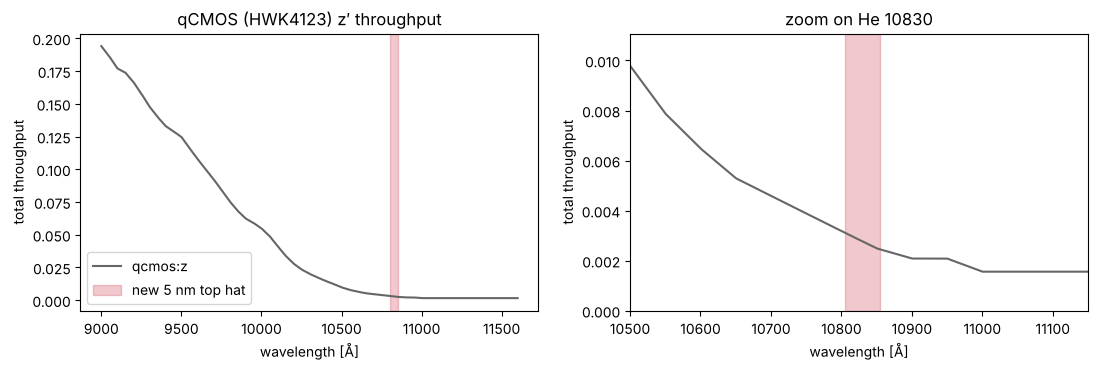

In [6]:
GAIN_MODES = ('high', 'low')
base = Simulation.from_sensorfilter(BASE_LABEL, star_scene(Z0))
W = np.arange(9000.0, 11600.0, 0.1)
T_base = base.sensor.bandpass(W).value
T_LINE = float(base.sensor.bandpass(LINE_WAVE).value)
MIN_FRAME = float(base.sensor.meta.get('min_frame_time', 0.008))
print(f"{BASE_LABEL}: pivot {float(base.sensor.bandpass.pivot().value):.0f} Å, total throughput at {LINE_WAVE:.0f} Å = {T_LINE:.4f} "
      f"(curve peak {T_base.max():.3f}); PSF {type(base.default_psf).__name__}; min frame {MIN_FRAME} s")
for gm in GAIN_MODES:
    sen = Simulation.from_sensorfilter(BASE_LABEL, star_scene(Z0), gain_mode=gm).sensor
    print(f"  gain {gm:4s}: read noise {sen.read_noise:.2f}, saturation {sen.saturation_e:.0f} ({sen.saturation_limit} limited), dark {sen.dark_current}")
if not T_LINE > 1e-5:
    raise RuntimeError(f"{BASE_LABEL} throughput is ~0 at {LINE_WAVE} Å: the shipped curve does not reach He 10830.")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 3.6))
for a in (ax, bx):
    a.plot(W, T_base, color='0.4', label=BASE_LABEL)
    a.axvspan(LINE_WAVE - FILTER_WIDTH / 2, LINE_WAVE + FILTER_WIDTH / 2, color='#d1495b', alpha=0.3, label='new 5 nm top hat')
    a.set(xlabel='wavelength [Å]', ylabel='total throughput')
bx.set(xlim=(10500, 11150), ylim=(0, 4 * T_LINE), title='zoom on He 10830')
ax.set(title='qCMOS (HWK4123) z′ throughput')
ax.legend()
plt.show()

**Build and install the filter.** `update_sensor()` only edits the sensor's parameter dictionary: the bandpass is read when the sensor is created. So we write the top hat in the format of the shipped curve and rebuild the qCMOS sensor on it with `set_sensor()`, keeping everything else from `from_sensorfilter` (scene, in-focus Airy PSF, gain mode).

In [7]:
from wcc_etc import get_sensor_config
from wcc_etc.io import expand_path

orig_path = Path(expand_path(base.sensor.meta['path_total_throughput']))
orig = pd.read_csv(orig_path)
wcol, tcol = orig.columns[:2]
w_file_nm, t_file = orig[wcol].to_numpy(float), orig[tcol].to_numpy(float)
probe_w = W[T_base > 0.2 * T_base.max()]
assert np.allclose(np.interp(probe_w / 10, w_file_nm, t_file), base.sensor.bandpass(probe_w).value, rtol=1e-3, atol=1e-6), \
    f'{orig_path.name} does not match the installed bandpass in nm'
print(f"{orig_path.name}: columns ({wcol}, {tcol}), wavelength in nm, {len(orig)} rows")

lo, hi = (LINE_WAVE - FILTER_WIDTH / 2) / 10, (LINE_WAVE + FILTER_WIDTH / 2) / 10        # nm
w_new = np.unique(np.r_[w_file_nm[(w_file_nm < lo - 0.1) | (w_file_nm > hi + 0.1)], lo - 1e-4, np.linspace(lo, hi, 101), hi + 1e-4])
t_new = np.where((w_new >= lo) & (w_new <= hi), np.interp(w_new, w_file_nm, t_file), 0.0)
TOPHAT_PATH = Path(tempfile.mkdtemp()) / 'wcc_qcmos_he10830_tophat_throughput.csv'
pd.DataFrame({wcol: w_new, tcol: t_new}).to_csv(TOPHAT_PATH, index=False)

def tophat_sim(scene, gain_mode='high'):
    # qcmos:z simulation (in-focus Airy PSF, HWK4123 noise model), sensor rebuilt on the top-hat throughput
    sim = Simulation.from_sensorfilter(BASE_LABEL, scene, gain_mode=gain_mode)
    cfg = get_sensor_config('qcmos', 'z', gain_mode=gain_mode)['sensor']
    cfg['path_total_throughput'] = str(TOPHAT_PATH)
    sim.set_sensor(cfg)
    return sim

nb = tophat_sim(star_scene(Z0))
T_nb = nb.sensor.bandpass(W).value
T_want = np.where(np.abs(W - LINE_WAVE) <= FILTER_WIDTH / 2, T_base, 0.0)
edge = np.abs(np.abs(W - LINE_WAVE) - FILTER_WIDTH / 2) < 0.6
assert np.allclose(T_nb[~edge], T_want[~edge], atol=1e-3 * T_LINE), 'the installed bandpass is not the top hat'
RECT = trapezoid(T_nb, W) / float(nb.sensor.bandpass(LINE_WAVE).value)
print(f"new filter installed: pivot {float(nb.sensor.bandpass.pivot().value):.1f} Å, rectangular width {RECT:.1f} Å, "
      f"T({LINE_WAVE:.0f}) = {float(nb.sensor.bandpass(LINE_WAVE).value):.4f}")

wcc_hwk_z_throughput.csv: columns (Wavelength, hwk_z), wavelength in nm, 161 rows
new filter installed: pivot 10829.0 Å, rectangular width 50.1 Å, T(10830) = 0.0028


**Does the ETC use it, and does it see a 0.1 Å line?** A line outside the top hat (10700 Å, still inside z′) must vanish, and a 0.1 Å line must give the same S/N as a 2 Å one (the filter is flat across both).

In [8]:
def line_scene(F, wave=LINE_WAVE, fwhm=LINE_FWHM, z=None):
    kw = {} if z is None else dict(host=STAR, host_prop={'mag': float(z), 'bandpass': MAG_BAND, 'magsys': MAG_SYS})
    return get_scene('emission', mag=None, lines=[{'wave': wave, 'flux': float(F), 'fwhm': fwhm}], **kw)

def snr_line(scene):
    try:
        return tophat_sim(scene).get_image_snr(T_EXP, warn=False)['snr']
    except ValueError as err:                  # wcc_etc refuses a source with no flux through the bandpass
        if 'no positive photon flux' in str(err):
            return 0.0
        raise

s_in, s_out, s_wide = snr_line(line_scene(1e-15)), snr_line(line_scene(1e-15, wave=10700.0)), snr_line(line_scene(1e-15, fwhm=2.0))
print(f"pure 1e-15 erg/s/cm2 line, 60 s: S/N {s_in:.1f} at 10830 Å (FWHM 0.1 Å), {s_wide:.1f} (FWHM 2 Å), {s_out:.2f} at 10700 Å")
assert s_out < 0.01 * s_in, 'a line outside the top hat is still detected: the filter is not applied'
assert np.isclose(s_in, s_wide, rtol=0.02), 'the 0.1 Å line is not sampled correctly by wcc_etc'

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


pure 1e-15 erg/s/cm2 line, 60 s: S/N 0.5 at 10830 Å (FWHM 0.1 Å), 0.5 (FWHM 2 Å), 0.00 at 10700 Å


**Precision versus magnitude.** The line is the source and the G2V star is a point-source host under it (WCC exercise 4), so `get_image_snr` returns the line S/N with the star's photon noise. Frames can be as short as 8 ms, so instead of trying read counts one by one (tutorial 05) the read count comes from the peak pixel (gallery notebook 10): the fewest reads per minute that keep the brightest pixel below 80 % of saturation. Both gain modes are run and the lower error kept. The star alone in the same filter gives the classic narrowband photometric precision, which must reproduce σ(EW) = σ_rel × rectangular width.

In [9]:
def reads_for(sim, t=T_EXP):
    # fewest reads per minute keeping the brightest pixel below 80 % of saturation; None if not possible
    peak = sim.get_peak_pixel(1.0, units='e-').value              # e- in the brightest pixel in 1 s
    tf = min(t, 0.8 * sim.sensor.saturation_e.value / peak)
    return None if tf < MIN_FRAME else int(np.ceil(t / tf))

SIMS = {gm: (tophat_sim(line_scene(line_flux(Z0), z=Z0), gm), tophat_sim(star_scene(Z0), gm)) for gm in GAIN_MODES}
wcc_sigF = np.full(Z_GRID.size, np.nan)
wcc_ppm = np.full(Z_GRID.size, np.nan)
wcc_reads = np.zeros(Z_GRID.size, int)
wcc_gain = [None] * Z_GRID.size
for i, z in enumerate(Z_GRID):
    F = line_flux(z)
    best = None
    for gm, (wl, ws) in SIMS.items():
        wl.update(host__mag=float(z))
        wl.update(source__lines=[{'wave': LINE_WAVE, 'flux': float(F), 'fwhm': LINE_FWHM}])
        n = reads_for(wl)
        if n is None:
            continue
        r = wl.get_image_snr(T_EXP, n_reads=n, warn=False)
        if r['saturated']:
            continue
        if best is None or F / r['snr'] < best[0]:
            ws.update(source__mag=float(z))
            best = (F / r['snr'], 1e6 / ws.get_image_snr(T_EXP, n_reads=n, warn=False)['snr'], n, gm)
    if best:
        wcc_sigF[i], wcc_ppm[i], wcc_reads[i], wcc_gain[i] = best
assert float(SIMS['high'][0].sensor.bandpass(LINE_WAVE + 40).value) < 1e-6, 'update() reverted the filter'
wcc_sigEW = wcc_sigF / fcont(Z_GRID)

ok = np.isfinite(wcc_sigF)
ratio = wcc_sigEW / (wcc_ppm * 1e-6 * RECT)
print(f"brightest unsaturated z' = {Z_GRID[ok][0]:.2f} ({wcc_reads[ok][0]} reads per minute, {wcc_gain[ok.argmax()]} gain)")
for gm in GAIN_MODES:
    zs = [z for z, g in zip(Z_GRID, wcc_gain) if g == gm]
    if zs:
        print(f"{gm} gain is better for z' = {min(zs):g}-{max(zs):g}")
print(f"sigma_EW (line run) / (star-only precision x {RECT:.1f} Å): median {np.nanmedian(ratio):.3f}, range {np.nanmin(ratio):.3f}-{np.nanmax(ratio):.3f}")
assert 0.9 < np.nanmedian(ratio) < 1.1

brightest unsaturated z' = 4.00 (533 reads per minute, high gain)
high gain is better for z' = 4-18
sigma_EW (line run) / (star-only precision x 50.1 Å): median 0.999, range 0.998-0.999


## 4. Comparison

σ(EW) per minute is independent of the line's strength wherever the star dominates the noise; the fractional accuracy of the reference line is σ(EW)/EW_ref.

In [10]:
print(f"1-minute flash, FWHM {LINE_FWHM} Å, reference EW {EW_REF * 1e3:.0f} mÅ (peak = {LINE_PEAK} x continuum)")
print(f"{'z_AB':>5} | {'IFS sigma_EW':>12} {'S/N_ref':>7} {'read-out':>16} | {'WCC sigma_EW':>12} {'S/N_ref':>7} {'gain':>4} {'reads':>5} {'ppm':>7} | {'IFS/WCC':>7}")
for zz in (4, 6, 8, 10, 12, 14, 16, 18):
    i = np.argmin(np.abs(Z_GRID - zz))
    a, b = ifs_sigEW[i] * 1e3, wcc_sigEW[i] * 1e3
    ro = f"{ifs_ro[i][0]}x{ifs_ro[i][1]}" if ifs_ro[i] else 'saturated'
    fa = f"{a:9.2f} mÅ {EW_REF * 1e3 / a:7.1f}" if np.isfinite(a) else f"{'sat':>12} {'':>7}"
    fb = f"{b:9.2f} mÅ {EW_REF * 1e3 / b:7.1f} {wcc_gain[i]:>4} {wcc_reads[i]:5d} {wcc_ppm[i]:7.0f}" if np.isfinite(b) else f"{'sat':>12} {'':>7} {'':>4} {'':>5} {'':>7}"
    print(f"{zz:5.1f} | {fa} {ro:>16} | {fb} | {a / b:7.2f}")

1-minute flash, FWHM 0.1 Å, reference EW 106 mÅ (peak = 1.0 x continuum)
 z_AB | IFS sigma_EW S/N_ref         read-out | WCC sigma_EW S/N_ref gain reads     ppm | IFS/WCC
  4.0 |          sat                saturated |     27.37 mÅ     3.9 high   533     547 |     nan
  6.0 |          sat                saturated |     68.77 mÅ     1.5 high    85    1373 |     nan
  8.0 |     46.00 mÅ     2.3     (2, 1, 0)x10 |    172.84 mÅ     0.6 high    14    3451 |    0.27
 10.0 |     84.07 mÅ     1.3      (7, 1, 0)x3 |    435.78 mÅ     0.2 high     3    8700 |    0.19
 12.0 |    199.13 mÅ     0.5     (21, 1, 0)x1 |   1119.46 mÅ     0.1 high     1   22351 |    0.18
 14.0 |    505.13 mÅ     0.2     (21, 1, 0)x1 |   3187.59 mÅ     0.0 high     1   63656 |    0.16
 16.0 |   1344.42 mÅ     0.1     (21, 1, 0)x1 |  12402.83 mÅ     0.0 high     1  247797 |    0.11
 18.0 |   4389.60 mÅ     0.0     (21, 1, 0)x1 |  67397.54 mÅ     0.0 high     1 1346879 |    0.07


## 5. A light curve with the flash (adapted from WCC tutorial 05)

Tutorial 05 draws white noise from the ETC S/N around a transit model. Here the model is the line EW: zero, except for the one exposure at t = 0. For the narrowband filter the same series in relative flux is $1 + \mathrm{EW}/W_\mathrm{rect}$. As in tutorial 05, only white noise is modelled.

In [11]:
Z_DEMO = 8.0                                   # about the brightest star the IFS takes unsaturated
i = np.argmin(np.abs(Z_GRID - Z_DEMO))
t_min = np.arange(-30, 31)                       # minutes, 1-minute cadence
ew_true = np.where(t_min == 0, EW_REF, 0.0)
rng = np.random.default_rng(3)
LC = {}
for name, sig in (('IFS', ifs_sigEW[i]), ('WCC 5 nm (qCMOS)', wcc_sigEW[i])):
    if np.isfinite(sig):
        LC[name] = (ew_true + rng.normal(0, sig, t_min.size), sig)
        quiet = LC[name][0][t_min != 0]
        print(f"{name:18s} z' = {Z_DEMO}: sigma_EW {sig * 1e3:6.2f} mÅ per minute, out-of-flash scatter {quiet.std() * 1e3:6.2f} mÅ, "
              f"flash at {EW_REF / sig:5.1f} sigma")
    else:
        print(f"{name:18s} z' = {Z_DEMO}: saturated")
if 'WCC 5 nm (qCMOS)' in LC:
    print(f"narrowband relative flux in the flash minute: 1 + {EW_REF / RECT * 1e6:.0f} ppm")

IFS                z' = 8.0: sigma_EW  46.00 mÅ per minute, out-of-flash scatter  49.95 mÅ, flash at   2.3 sigma
WCC 5 nm (qCMOS)   z' = 8.0: sigma_EW 172.84 mÅ per minute, out-of-flash scatter 188.17 mÅ, flash at   0.6 sigma
narrowband relative flux in the flash minute: 1 + 2124 ppm


## Hero figure

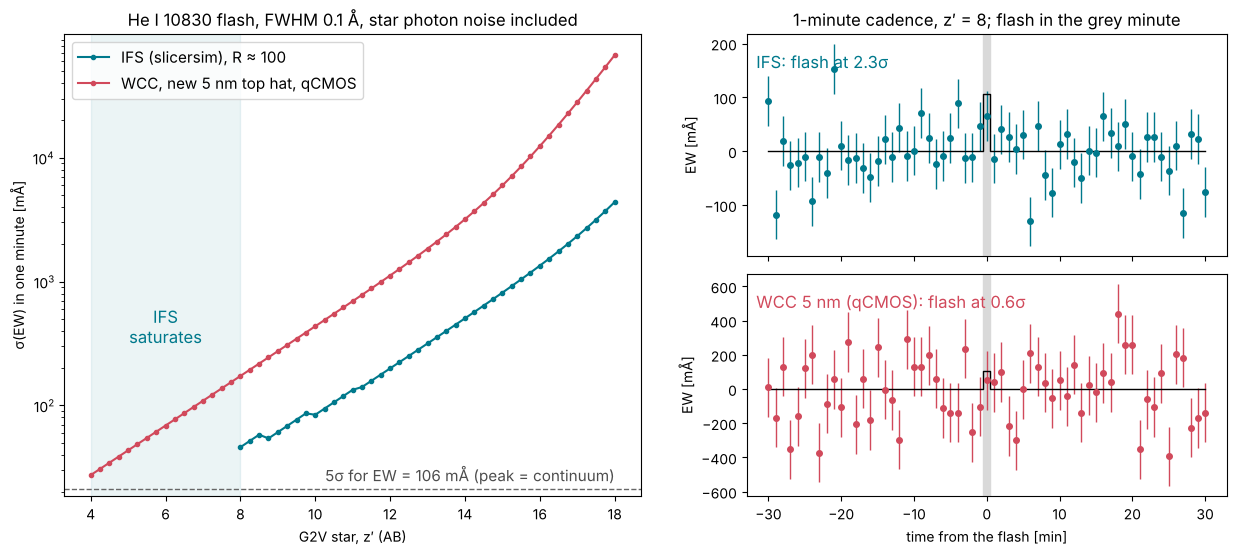

In [12]:
cols = {'IFS': '#00798c', 'WCC 5 nm (qCMOS)': '#d1495b'}
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], hspace=0.08)
ax = fig.add_subplot(gs[:, 0])
ax.semilogy(Z_GRID, ifs_sigEW * 1e3, 'o-', ms=3, color=cols['IFS'], label='IFS (slicersim), R ≈ 100')
ax.semilogy(Z_GRID, wcc_sigEW * 1e3, 'o-', ms=3, color=cols['WCC 5 nm (qCMOS)'], label='WCC, new 5 nm top hat, qCMOS')
ax.axhline(EW_REF * 1e3 / 5, color='0.4', ls='--', lw=1)
ax.text(Z_GRID[-1], EW_REF * 1e3 / 5 * 1.15, f'5σ for EW = {EW_REF * 1e3:.0f} mÅ (peak = continuum)', color='0.3', fontsize=11, ha='right')
for name, arr in (('IFS', ifs_sigEW), ('WCC 5 nm (qCMOS)', wcc_sigEW)):
    ok = np.isfinite(arr)
    if ok.any() and not ok[0]:
        ax.axvspan(Z_GRID[0], Z_GRID[ok][0], color=cols[name], alpha=0.08)
        ax.text(0.5 * (Z_GRID[0] + Z_GRID[ok][0]), EW_REF * 1e3 * 3, f'{name.split()[0]}\nsaturates', ha='center', color=cols[name], fontsize=12)
ax.set(xlabel='G2V star, z′ (AB)', ylabel='σ(EW) in one minute [mÅ]', title='He I 10830 flash, FWHM 0.1 Å, star photon noise included')
ax.legend(loc='upper left', fontsize=11)

for k, (name, (ew, sig)) in enumerate(LC.items()):
    bx = fig.add_subplot(gs[k, 1])
    bx.axvspan(-0.5, 0.5, color='0.85', zorder=0)
    bx.errorbar(t_min, ew * 1e3, yerr=sig * 1e3, fmt='o', ms=4, color=cols[name], capsize=0, lw=1)
    bx.step(t_min, ew_true * 1e3, where='mid', color='k', lw=1)
    bx.text(0.02, 0.92, f"{name}: flash at {EW_REF / sig:.1f}σ", transform=bx.transAxes, va='top', fontsize=12, color=cols[name])
    bx.set(ylabel='EW [mÅ]')
    if k == 0:
        bx.set_title(f"1-minute cadence, z′ = {Z_DEMO:g}; flash in the grey minute")
        bx.tick_params(labelbottom=False)
    else:
        bx.set_xlabel('time from the flash [min]')
fig.savefig(THUMB, dpi=150, bbox_inches='tight')
plt.show()

## Answer

For a 0.1 Å-FWHM He I 10830 flash whose peak equals the continuum (EW ≈ 106 mÅ), **neither instrument detects a single 1-minute flash at 5σ on a G2V star**; the brightest usable stars come closest (numbers from slicersim 1.4.2 and wcc_etc 0.1.1):

- **IFS:** σ(EW) ≈ 46 mÅ per minute at z′ = 8, the brightest star it takes without saturating (ten 5.7 s ramps), i.e. S/N ≈ 2.3 for the reference line; 84 mÅ at z′ = 10, 0.2 Å at z′ = 12, 0.5 Å at z′ = 14. The star's photon noise dominates down to z′ ≈ 14 with the full-minute ramp.
- **WCC, new 5 nm filter on the qCMOS (HWK4123):** 4–6× worse than the IFS at the same magnitude for z′ = 8–14 (more for fainter stars), because the qCMOS z′ total throughput at 1.083 µm is only 0.28 % (silicon QE) and the filter is half as wide as the IFS line window. Its advantage is the bright end: high gain with 0.11 s frames (533 reads per minute) keeps a z′ = 4 star unsaturated, where σ(EW) ≈ 27 mÅ (S/N ≈ 3.9). High gain beats low gain at every magnitude.

A 5σ single-minute detection therefore needs EW ≳ 0.14 Å on a z′ = 4 star with the WCC filter, or ≳ 0.23 Å on a z′ = 8 star with the IFS; equivalently, for this line shape, a peak 1.3–2.2× the continuum. Stronger or longer-lived flashes, or flashes on brighter stars (for the WCC), are needed.

## Caveats & next steps

- **The filter is hypothetical.** It is a perfect 50 Å top hat whose transmission equals the z′ filter's at 1.08 µm, on the shipped `qcmos:z` telescope × QE curve. Check the HWK4123 QE at 1083 nm against the datasheet: silicon QE falls steeply here, and the answer scales with it. Real interference filters have lower peak transmission, sloped edges, and a passband that shifts with the angle of incidence across the field.
- **Continuum knowledge.** Both instruments assume the quiescent continuum is known from the exposures before the flash (the light-curve baseline). A single narrowband filter cannot tell line emission from a continuum change in the same minute (a white-light flare would look like He I emission); the IFS measures the continuum beside the line in the same exposure. An off-line WCC filter, or a simultaneous broadband WCC image, would be the fix.
- **PSF.** In-focus Airy PSF, which `wcc_etc` evaluates at the source-weighted effective wavelength, i.e. at ≈ 1.08 µm in the new filter.
- **IFS measurement.** Point source in the narrow field; a box sum over ±1 LSF FWHM that loses the LSF wings (the recovered fraction is printed and corrected for), against the noise-free continuum. The fixed read-out list is a choice; `setup_to_snr` or other MACC modes may do slightly better.
- **White noise only**, as in tutorial 05: no flat-field, jitter or gain-drift floor, no saturation non-linearity or persistence.
- **Line shape.** The star's photospheric Si I 10827 Å line sits inside the filter; it is constant and cancels in the difference. Flare He I emission is often broader and shifted by tens of km/s (≲ 1 Å); both instruments still capture it.
- *Extend it:* (1) add an off-line continuum filter at 10700 Å and fold its noise in; (2) sweep the filter width from 1 to 10 nm; (3) move the star to an M dwarf, where He 10830 activity is stronger and the continuum redder; (4) put the flash in the IFS wide field.